![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/05/logo-upv-horizontal.png)
![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/06/logos-perte-chip-1024x119.png)


# Laboratory 3. Interferometers I - MZI


Today we will work on the design and modeling of an **Mach-Zenhder Interferometer (MZI)** used in integrated photonic circuits. We will perform simulations that will allow us to understand how it operates.


## 0.1 General libraries

In [ ]:
import gdsfactory as gf # If we deal with a MZ in a PDK, we will have tu use this
import jax # Mathematical tools, like the parent version of sax
import jax.example_libraries.optimizers as opt
import jax.numpy as jnp
import matplotlib.pyplot as plt
from matplotlib.pyplot import cm

import numpy as np
import sax
from gdsfactory.generic_tech import get_generic_pdk
from scipy import constants
from scipy.constants import c
from scipy.interpolate import interp1d

import gplugins.sax as gs
from gplugins.common.config import PATH

C:\Users\cfp\AppData\Local\Temp\ipykernel_13924\3896563056.py:10: DeprecationWarning: The 'gdsfactory.generic_tech' module is deprecated and will be removed in a future version. Please update your imports to use 'gdsfactory.gpdk' instead:
  from gdsfactory.gpdk import LAYER, LAYER_STACK, get_generic_pdk
Or for submodules:
  from gdsfactory.gpdk.layer_map import LAYER
  from gdsfactory.gpdk.layer_stack import LAYER_STACK
  from gdsfactory.generic_tech import get_generic_pdk


## 1. MZI modeling
Let's compute the transfer function of a MZI

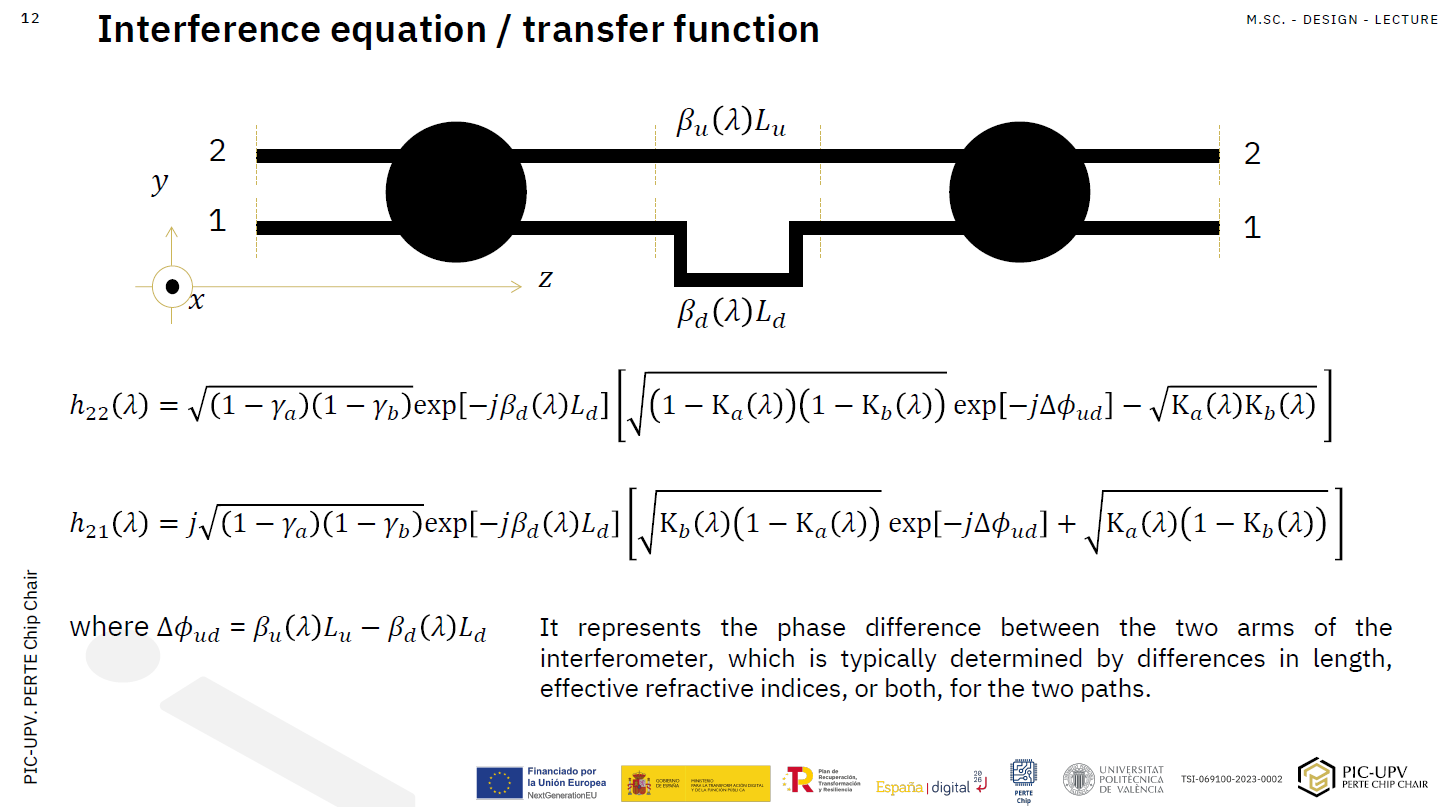

In [54]:
### Waveguides configuration ###

## Propagation parameters

## SOI cross-section ##
SOI = np.loadtxt('SOI-w450-h220-clad600.txt', skiprows=1, delimiter='\t')

wvl = SOI[:, 0]
neffu = SOI[:, 3] #balanced configuration // (neff TE mode) upper arm
neffd = SOI[:, 3] #balanced configuration // (neff TE mode) under arm

## SiN cross-section ##
# SiN_clad = np.loadtxt('SiN-h300nm-w1000nm-Cladding.txt', skiprows=1, delimiter='\t')
# SiN_wat = np.loadtxt('SiN-h300nm-w1000nm-Water.txt', skiprows=1, delimiter='\t')

# wvl0 = SiN_clad[:, 0]
# neffu0 = SiN_clad[:, 3] #balanced configuration // (neff TE mode)
# neffd0 = SiN_wat[:, 3] #balanced configuration // (neff TE mode)

# interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
# interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
# wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
# neffu = interp_neffu(wvl)
# neffd = interp_neffd(wvl)
def mathematical_MZ(wvl, alphau, alphad, Lu, Ld,
                    neffu, neffd,
                    gamma_a, gamma_b,
                    K_a, K_b ,
                    title = 'MZI Transfer function',
                    nm = False):
    # Propagation lossof each arm
    #alphau = 0 #losless case [dB/um]
    #alphad = 0; #losless case [dB/um]
    alphau_np = (jnp.log(10.0)/10.0) * alphau   # neper/um
    alphad_np = (jnp.log(10.0)/10.0) * alphad   # neper/um

    # Path length
    #Lu = 25; # um
    #Ld = 5; # um

    betau = (2*jnp.pi/wvl)*neffu-1j*alphau_np
    betad = (2*jnp.pi/wvl)*neffd-1j*alphad_np

    Delta_phi_ud = betau*Lu - betad*Ld

    ### Couplers configuration ###
    # Excess loss
    gamma_a = gamma_a; #null excess loss
    gamma_b = gamma_b; #null excess loss

    # Coupling constant
    K_a = K_a
    K_b = K_b

    # MZI transfer function (h22 & h21)

    #  h_22(wvl)
    h_22 = (np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*(( np.sqrt((1 - K_a) * (1 - K_b)) * np.exp(-1j * Delta_phi_ud))-(np.sqrt(K_a * K_b)))

    #  h_21(wvl)
    h_21 = (1j * np.sqrt((1 - gamma_a) * (1 - gamma_b)))*(np.exp(-1j * betad * Ld))*((np.sqrt(K_b * (1 - K_a)) * np.exp(-1j * Delta_phi_ud))+(np.sqrt(K_a * (1 - K_b))))

    H21 = np.abs(h_21) ** 2
    H22 = np.abs(h_22) ** 2

    # Plot
    color = cm.rainbow(np.linspace(0, 1, 10))
    if nm == True:
        wvl = wvl*1000
    plt.plot(wvl, H22, linestyle='-', color=color[1], label='H22')
    plt.plot(wvl, H21, linestyle='--', color=color[1], label='H21')
    plt.xlabel('Wvl (um)')
    plt.ylabel('|H|')
    plt.title(title)
    plt.legend()
    plt.grid(True)

    plt.show()

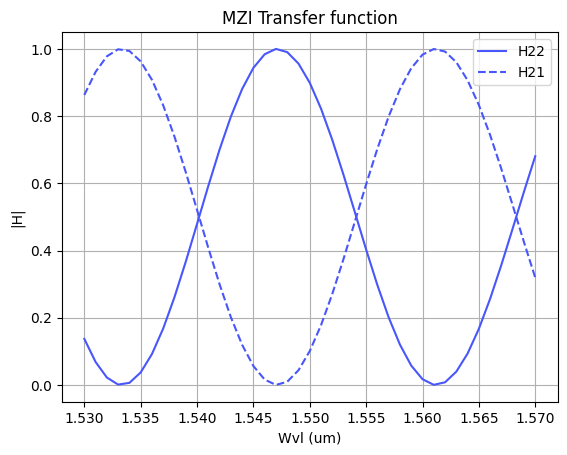

In [ ]:
## SOI cross-section ##
SOI = np.loadtxt('SOI-w450-h220-clad600.txt', skiprows=1, delimiter='\t')

wvl = SOI[:, 0]
neffu = SOI[:, 3] #balanced configuration // (neff TE mode) upper arm
neffd = SOI[:, 3] #balanced configuration // (neff TE mode) under arm

# Parameters arms
alphau = 0
Lu = 25
alphad = 0
Ld = 5

# Parameters couplers
gamma_a = 0
gamma_b = 0
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.5)


mathematical_MZ(
    wvl ,alphau, alphad, # Losses uper and down arm, respectively
    Lu, Ld, # Length upper and down arm, respectively
    neffu, neffd, # Effective indexes of each arm
    gamma_a, gamma_b, # Excess losses of coupler a and b
    K_a, K_b, # coupling constant of each coupler
    title = 'MZI Transfer function'
)

**Assesment 1.** Please, provide one example of each one of the configurations studied during MZI lecture:
1. Balenced configuration
2. Unbalanced configuration
  1.   Phase difference
  2.   Delay imbalance

### Balanced

### Unbalanced

Well, as in 3 and 4 ask us for the usuals unbalanced types let's do here a amplitude imbalance interferometer. For that, we are going to consider two different couplers and two different waveguide lengths

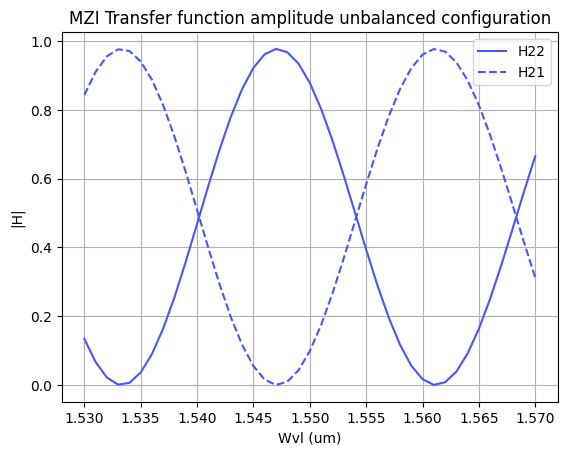

In [ ]:
## SOI cross-section ##
SOI = np.loadtxt('SOI-w450-h220-clad600.txt', skiprows=1, delimiter='\t')

wvl = SOI[:, 0]
neffu = SOI[:, 3] #balanced configuration // (neff TE mode) upper arm
neffd = SOI[:, 3] #balanced configuration // (neff TE mode) under arm

# Parameters arms
alphau = 0
Lu = 5
alphad = 0
Ld = 25

# Parameters couplers
gamma_a = 0
gamma_b = 0.0228
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.5)


mathematical_MZ(
    wvl, alphau, alphad, # Losses uper and down arm, respectively
    Lu, Ld, # Length upper and down arm, respectively
    neffu, neffd, # Effective indexes of each arm
    gamma_a, gamma_b, # Excess losses of coupler a and b
    K_a, K_b, # coupling constant of each coupler
    title = 'MZI Transfer function amplitude unbalanced configuration'
)

In this case. introducing excess loss to one coupler we see hoy the output power decrease, wich is a logical thing. What happens is the two couplers don't have the same K?

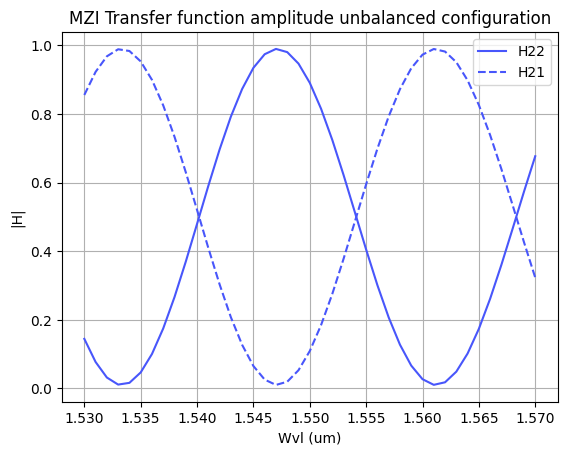

In [33]:
## SOI cross-section ##
SOI = np.loadtxt('SOI-w450-h220-clad600.txt', skiprows=1, delimiter='\t')

wvl = SOI[:, 0]
neffu = SOI[:, 3] #balanced configuration // (neff TE mode) upper arm
neffd = SOI[:, 3] #balanced configuration // (neff TE mode) under arm

# Parameters arms
alphau = 0
Lu = 5
alphad = 0
Ld = 25

# Parameters couplers
gamma_a = 0
gamma_b = 0
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.6)


mathematical_MZ(
    wvl, alphau, alphad, # Losses uper and down arm, respectively
    Lu, Ld, # Length upper and down arm, respectively
    neffu, neffd, # Effective indexes of each arm
    gamma_a, gamma_b, # Excess losses of coupler a and b
    K_a, K_b, # coupling constant of each coupler
    title = 'MZI Transfer function amplitude unbalanced configuration'
)

We can see that just ass adding excess losses to the couplers, not having a 0.5 K in one coupler reduces the power of the utputs but in a smaller way that adding excess losses (sure this will deppend on the exact values of K and gamma). However, in our design lab of MMi we saw that even thought we can have a not perfect K MMI maybe it has 0.51-0.52 K and for those values the power decrease is minimmal. However, for 0.0228 gamma (a 0.1 dB excess loss) we see a bigger effect of the power loss in teh outputs

#### Phase difference

For this case, we are gonna select in one arm SiN in cladding as a usual waveguide and in the other one, SiN in water

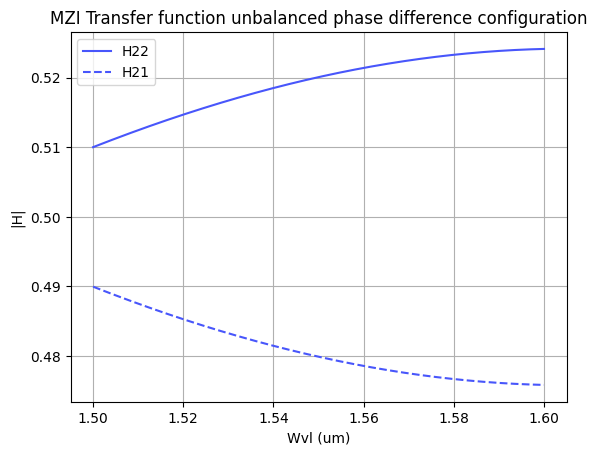

In [38]:
## SiN cross-section ##
SiN_clad = np.loadtxt('SiN-h300nm-w1000nm-Cladding.txt', skiprows=1, delimiter='\t')
SiN_wat = np.loadtxt('SiN-h300nm-w1000nm-Air.txt', skiprows=1, delimiter='\t')

wvl0 = SiN_clad[:, 0]
neffu0 = SiN_clad[:, 3] #balanced configuration // (neff TE mode)
neffd0 = SiN_wat[:, 3] #balanced configuration // (neff TE mode)

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
neffu = interp_neffu(wvl)
neffd = interp_neffd(wvl)



# Parameters arms
alphau = 0
Lu = 5
alphad = 0
Ld = 5

# Parameters couplers
gamma_a = 0
gamma_b = 0
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.5)


mathematical_MZ(
    wvl, alphau, alphad, # Losses uper and down arm, respectively
    Lu, Ld, # Length upper and down arm, respectively
    neffu, neffd, # Effective indexes of each arm
    gamma_a, gamma_b, # Excess losses of coupler a and b
    K_a, K_b, # coupling constant of each coupler
    title = 'MZI Transfer function unbalanced phase difference configuration'
)

So the phase difference induced by the difference of index is so small that even we can see the interferometric patter, the extintion rate of the outputs is to small (being extintion rate the deep of the dip). How can we amplify this effect? Doing a fuly unbalanced arm,i.e., also introducing phase delay thakns to a difference of the length of the arms

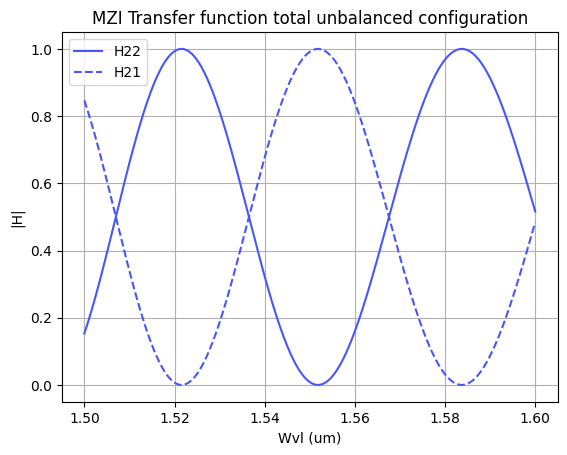

In [40]:
## SiN cross-section ##
SiN_clad = np.loadtxt('SiN-h300nm-w1000nm-Cladding.txt', skiprows=1, delimiter='\t')
SiN_wat = np.loadtxt('SiN-h300nm-w1000nm-Air.txt', skiprows=1, delimiter='\t')

wvl0 = SiN_clad[:, 0]
neffu0 = SiN_clad[:, 3] #balanced configuration // (neff TE mode)
neffd0 = SiN_wat[:, 3] #balanced configuration // (neff TE mode)

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
neffu = interp_neffu(wvl)
neffd = interp_neffd(wvl)



# Parameters arms
alphau = 0
Lu = 5
alphad = 0
Ld = 25

# Parameters couplers
gamma_a = 0
gamma_b = 0
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.5)


mathematical_MZ(
    wvl, alphau, alphad, # Losses uper and down arm, respectively
    Lu, Ld, # Length upper and down arm, respectively
    neffu, neffd, # Effective indexes of each arm
    gamma_a, gamma_b, # Excess losses of coupler a and b
    K_a, K_b, # coupling constant of each coupler
    title = 'MZI Transfer function total unbalanced configuration'
)

And yeah, now we can see how the effect have been amplified. Also, note that changing the difference of effective index between the waveguides the spectrum of the device shifted in wavelength! 

#### Phase delay

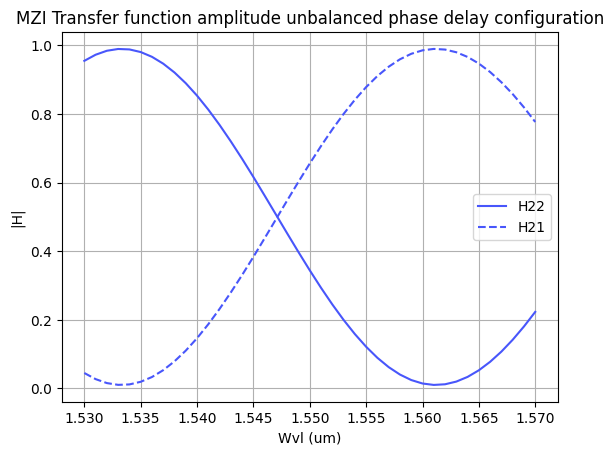

In [42]:
## SOI cross-section ##
SOI = np.loadtxt('SOI-w450-h220-clad600.txt', skiprows=1, delimiter='\t')

wvl = SOI[:, 0]
neffu = SOI[:, 3] #balanced configuration // (neff TE mode) upper arm
neffd = SOI[:, 3] #balanced configuration // (neff TE mode) under arm

# Parameters arms
alphau = 0
Lu = 5
alphad = 0
Ld = 15

# Parameters couplers
gamma_a = 0
gamma_b = 0
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.6)


mathematical_MZ(
    wvl, alphau, alphad, # Losses uper and down arm, respectively
    Lu, Ld, # Length upper and down arm, respectively
    neffu, neffd, # Effective indexes of each arm
    gamma_a, gamma_b, # Excess losses of coupler a and b
    K_a, K_b, # coupling constant of each coupler
    title = 'MZI Transfer function amplitude unbalanced phase delay configuration'
)

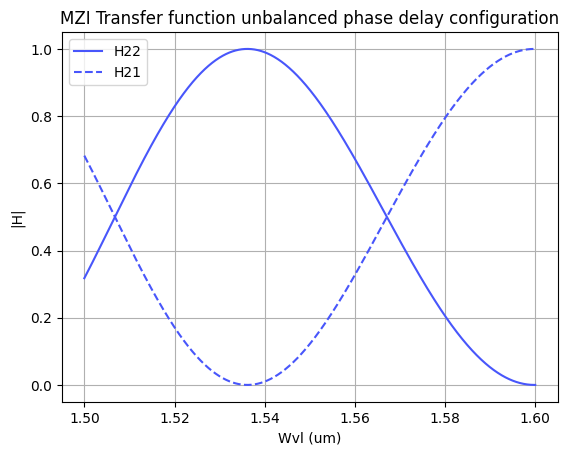

In [46]:
## SiN cross-section ##
SiN_clad = np.loadtxt('SiN-h300nm-w1000nm-Cladding.txt', skiprows=1, delimiter='\t')
SiN_wat = np.loadtxt('SiN-h300nm-w1000nm-Air.txt', skiprows=1, delimiter='\t')

wvl0 = SiN_clad[:, 0]
neffu0 = SiN_clad[:, 3] #balanced configuration // (neff TE mode)
neffd0 = SiN_wat[:, 3] #balanced configuration // (neff TE mode)

interp_neffu = interp1d(wvl0, neffu0, kind='cubic')  # Cubic interpolation for smoothness
interp_neffd = interp1d(wvl0, neffd0, kind='cubic')
wvl = np.linspace(wvl0.min(), wvl0.max(), 1000)
neffu = interp_neffu(wvl)
neffd = interp_neffd(wvl)



# Parameters arms
alphau = 0
Lu = 5
alphad = 0
Ld = 15

# Parameters couplers
gamma_a = 0
gamma_b = 0
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.5)


mathematical_MZ(
    wvl, alphau, alphad, # Losses uper and down arm, respectively
    Lu, Ld, # Length upper and down arm, respectively
    neffu, neffd, # Effective indexes of each arm
    gamma_a, gamma_b, # Excess losses of coupler a and b
    K_a, K_b, # coupling constant of each coupler
    title = 'MZI Transfer function unbalanced phase delay configuration'
)

What we see? Changing the path difference between arms changes the space between resonence, i.e., the free spectral range

**Assesment 2.** Taking into account the n_{eff} values for the SOI cross-section, what would be the path difference ($\Delta L$ = $L_u$ - $L_d$) needed to obtain a Free Spectral Range of 40 nm? Introduce the obtained value in the model to check the MZI response. Hint: We assume 1550 nm as the central design wavelength ($\lambda _0$=1550 nm).

We know from theory classes that the FSR is equal to $\frac{\lambda^2}{n_g (\lambda) \Delta L}$. To compute the group index of SOI technology we can do $n_g (\lambda)  = \bar{n} - \lambda \frac{\partial \bar{n}(\lambda)}{\partial \lambda}$

In [57]:
## SOI cross-section ##
SOI = np.loadtxt('SOI-w450-h220-clad600.txt', skiprows=1, delimiter='\t')
lambda_0 = 1.55
nm = 1000
wvl = SOI[:, 0]
neffu = SOI[:, 3] #balanced configuration // (neff TE mode) upper arm
neffd = SOI[:, 3] #balanced configuration // (neff TE mode) under arm

n_g = np.mean(neffu) - lambda_0*(np.gradient(neffu)/np.gradient(wvl))
print(f'Group index of SOI for {lambda_0} nm is {n_g[20]}')
n_g_1550 = n_g[20]


Group index of SOI for 1.55 nm is 4.293262926829225


In [58]:
FSR = 40 #nm
DeltaL = (lambda_0*nm)**2/(n_g_1550*FSR)
print(f'The path difference needed for a FSR of {FSR} nm is {DeltaL/1000} um')

The path difference needed for a FSR of 40 nm is 13.989942154406778 um


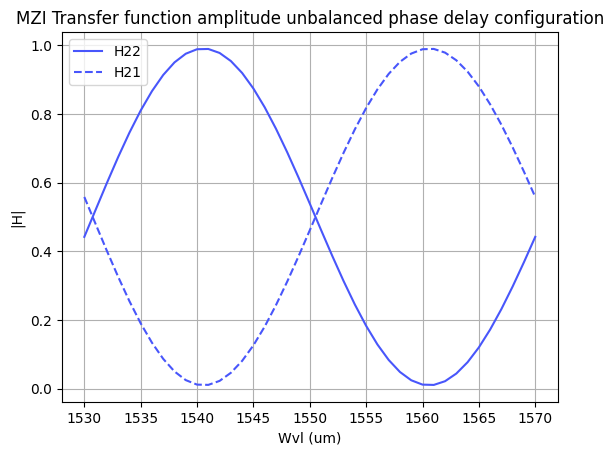

In [56]:
# Parameters arms
alphau = 0
Lu = 5
alphad = 0
Ld = 5 + DeltaL/1000

# Parameters couplers
gamma_a = 0
gamma_b = 0
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.6)


mathematical_MZ(
    wvl, alphau, alphad, # Losses uper and down arm, respectively
    Lu, Ld, # Length upper and down arm, respectively
    neffu, neffd, # Effective indexes of each arm
    gamma_a, gamma_b, # Excess losses of coupler a and b
    K_a, K_b, # coupling constant of each coupler
    title = 'MZI Transfer function amplitude unbalanced phase delay configuration',
    nm = True
)

It seems that yes, we have a FSR of 40 nm but is out of our window, let's induce a phase difference in one arm to shift the spectrum and see the FSR

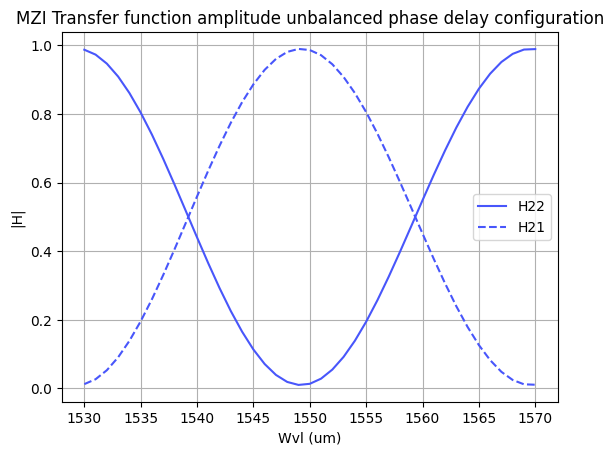

In [78]:
# Parameters arms
alphau = 0
Lu = 5
alphad = 0
Ld = 5 + DeltaL/1000

# Parameters couplers
gamma_a = 0
gamma_b = 0
K_a = np.full(wvl.shape, 0.5)
K_b = np.full(wvl.shape, 0.6)


mathematical_MZ(
    wvl, alphau, alphad, # Losses uper and down arm, respectively
    Lu, Ld, # Length upper and down arm, respectively
    neffu, neffd-0.023, # Effective indexes of each arm
    gamma_a, gamma_b, # Excess losses of coupler a and b
    K_a, K_b, # coupling constant of each coupler
    title = 'MZI Transfer function amplitude unbalanced phase delay configuration',
    nm = True
)

And here we go, we can see the distance of approximately 40 nm between the two maximun values

## 2. MZI simulation implemented with SAX
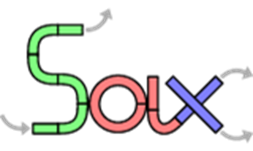

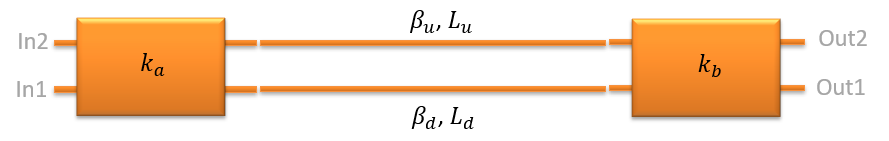


### 2.1 Components S matrix


In [72]:
# Waveguide Model

def waveguide(wl=1.55, neff=1.6072, length=10.0, loss=0.0) -> sax.SDict:
    phase = 2 * jnp.pi * neff * length / wl
    transmission = 10 ** (-loss * length / 20) * jnp.exp(1j * phase) # loss(dB/um)
    wg_dict = sax.reciprocal(
        {
            ("in0", "out0"): transmission,
        }
    )
    return wg_dict


# Coupler Model

def coupler(coupling=0.5) -> sax.SDict:
    kappa = coupling**0.5
    tau = (1 - coupling) ** 0.5
    coupler_dict = sax.reciprocal(
        {
            ("in0", "out0"): tau,
            ("in0", "out1"): kappa * np.exp(-1j * np.pi / 2.0),
            ("in1", "out0"): kappa * np.exp(-1j * np.pi / 2.0),
            ("in1", "out1"): tau,
        }
    )
    return coupler_dict

### 2.2 MZI SAX Circuit Model

In [73]:
# MZI

mzi, info = sax.circuit(
    netlist={
        "instances": {
            "coup_a": "coupler",
            "wvg_u": "waveguide",
            "wvg_d": "waveguide",
            "coup_b": "coupler",
        },
        "connections": {
            "coup_a,out0": "wvg_d,in0",
            "wvg_d,out0": "coup_b,in0",
            "coup_a,out1": "wvg_u,in0",
            "wvg_u,out0": "coup_b,in1",
        },
        "ports": {
            "in0": "coup_a,in0",
            "in1": "coup_a,in1",
            "out0": "coup_b,out0",
            "out1": "coup_b,out1",
        },
    },
    models={
        "coupler": coupler,
        "waveguide": waveguide,
    },
)


### 2.3. MZI Modeling
**Assesment 3**: Now, we are going to implement the design parameters in the MZI model developed in SAX and compare the response obtained with that simulated by mathematical formulation.

This will help us to identify any error in the definition of the SAX model single components.

In order to implement the SAX model, take as example the following lines:

    mzi_test = mzi(wl=wl,
                coup_a = ...
                wvg_d={"length": l_d, "neff": ...},
                wvg_u={"length": l_u, "neff": ...},
                coup_b = ... )

    H00 = mzi_test["in0", "out0"]

In [ ]:
mzi_test = mzi(wl=wvl,
            coup_a={"coupling":K_a},
            wvg_u={"wl":wvl, "neff":neffu, "length": Lu, "loss":alphau},
            wvg_d={"wl":wvl, "neff":neffd, "length": Ld, "loss":alphad},
            coup_b={"coupling":K_b},
            )

h00 = mzi_test["in0", "out0"]
h01 = mzi_test["in0", "out1"]
h11 = mzi_test["in1", "out1"]
h10 = mzi_test["in1", "out0"]


# Plot
color = cm.rainbow(np.linspace(0, 1, 10))
plt.figure()
plt.plot(wvl, np.abs(h11)**2, linestyle="-", color=color[8], label=f"h11")
plt.plot(wvl, np.abs(h10)**2, linestyle="--", color=color[8], label=f"h10")
# Values of the mathematical mode
#plt.plot(wvl, H22, linestyle='-', color=color[1], label='H22')
#plt.plot(wvl, H21, linestyle='--', color=color[1], label='H21')
plt.xlabel('Wvl (um)')
plt.ylabel('|H|')
plt.title('MZI Transfer function')
plt.grid(True)
plt.show()

**Assessment 4.** Designing an MZI for filtering at a specific wavelength. Calculate and adjust the arm lengths to configure the MZI to have a maximum transmission at 1550 nm.

In [80]:
## SOI cross-section ##
SOI = np.loadtxt('SOI-w450-h220-clad600.txt', skiprows=1, delimiter='\t')
lambda_0 = 1.55
nm = 1000
wvl = SOI[:, 0]
neffu = SOI[:, 3] #balanced configuration // (neff TE mode) upper arm
neffd = SOI[:, 3] #balanced configuration // (neff TE mode) under arm
neffu_1550 = neffu[20]

# To have maximun in a lambda, the phase difference must be 2pi, considering equal material arms
DeltaL = lambda_0/neffu_1550
print(f'The length difference to have a maximun for {lambda_0*1000} nm is {DeltaL} um ')

The length difference to have a maximun for 1550.0 nm is 0.6579589688297245 um 


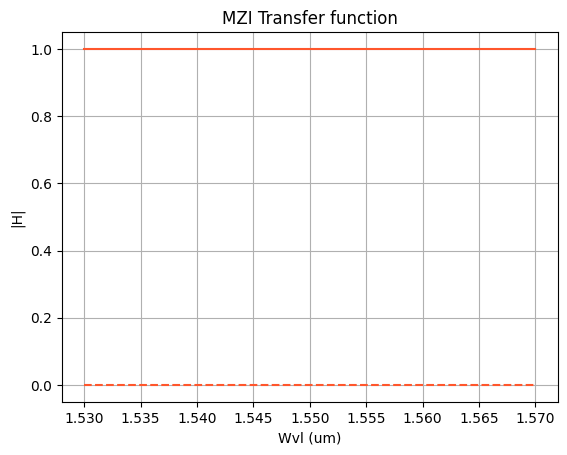

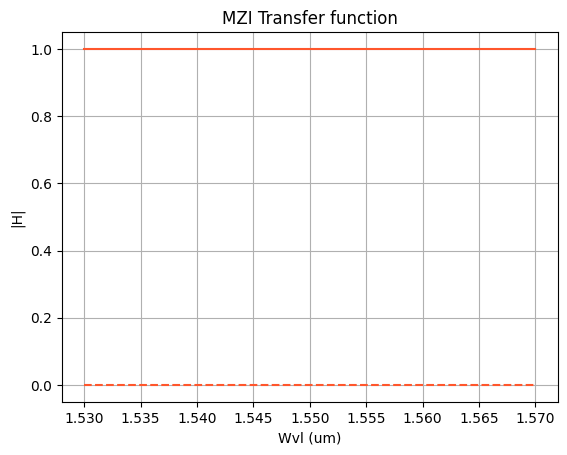

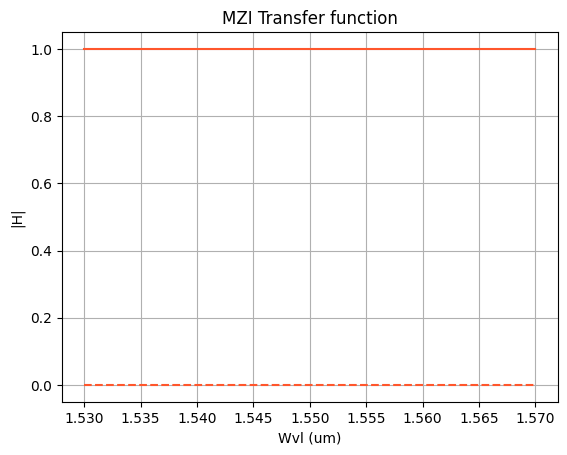

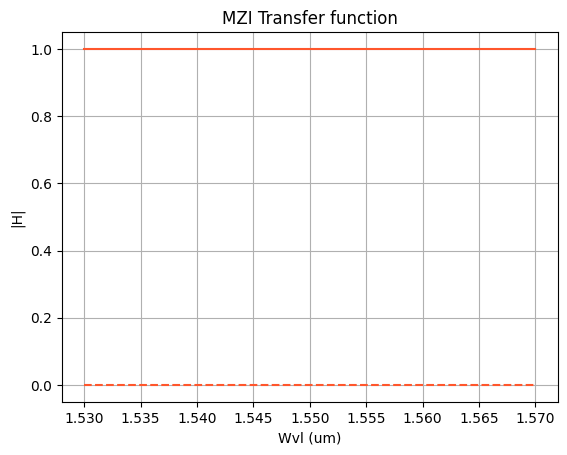

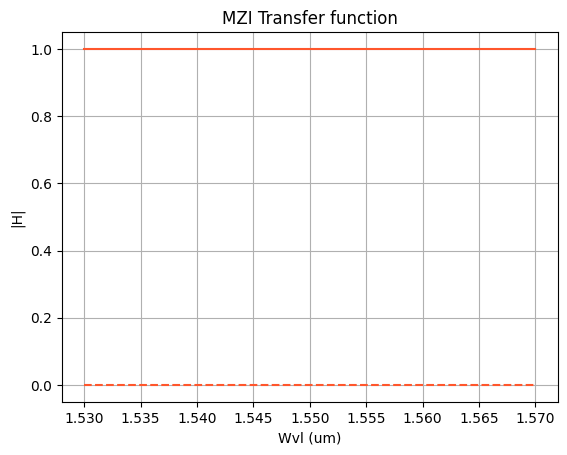

In [83]:
# Coupling
K_a = 0
K_b = 0
Lu = 5
alphau = 0
alphad = 0

for m in np.arange(0,10,2):
    Ld = Lu + m*DeltaL
    mzi_test = mzi(wl=wvl,
                coup_a={"coupling":K_a},
                wvg_u={"wl":wvl, "neff":neffu, "length": Lu, "loss":alphau},
                wvg_d={"wl":wvl, "neff":neffd, "length": Ld, "loss":alphad},
                coup_b={"coupling":K_b},
                )

    h00 = mzi_test["in0", "out0"]
    h01 = mzi_test["in0", "out1"]
    h11 = mzi_test["in1", "out1"]
    h10 = mzi_test["in1", "out0"]


    # Plot
    color = cm.rainbow(np.linspace(0, 1, 10))
    plt.figure()
    plt.plot(wvl, np.abs(h11)**2, linestyle="-", color=color[8], label=f"h11")
    plt.plot(wvl, np.abs(h10)**2, linestyle="--", color=color[8], label=f"h10")
    # Values of the mathematical mode
    #plt.plot(wvl, H22, linestyle='-', color=color[1], label='H22')
    #plt.plot(wvl, H21, linestyle='--', color=color[1], label='H21')
    plt.xlabel('Wvl (um)')
    plt.ylabel('|H|')
    plt.title('MZI Transfer function')
    plt.grid(True)
    plt.show()

**Assessment 5.** Let's see how the response of the MZI variates with the effective index. Vary the effective index of one of the arms and analyze how the spectrum shifts. To do this, you can use the data provided in the .txt files entitled ‘SiN’.
Can you give an example of an application where this configuration is used?

**Assessment 6.** Explore how cascading two MZIs affects the transmission spectrum. To do so, design a system in which two MZIs are cascaded. Simulate and observe the spectrum, explaining how the transmission peaks behave.